# Engineering Enrollment and Wages: Full-Information Estimation of the Ryoo–Rosen Model

This notebook reproduces every number, table, and figure in the paper, starting from the two data files and ending with the comparison of rational and cobweb expectations. It follows the order of the paper:

1. **Data** – build the three observed series and detrend them (Section 3, Figure 1).
2. **Model solution** – write the planning problem in linear-quadratic form and solve the Riccati equation (Section 2, Appendix A).
3. **Likelihood** – put the solution and the measurement errors into state-space form and evaluate the likelihood with the Kalman filter (Section 4.1, Algorithm 1, Appendix B).
4. **Estimation** – maximum likelihood, standard errors, profile likelihood intervals, and the test of real roots (Section 4.2, Table 1, Figure 2).
5. **Model fit** – population moments and simulated samples (Section 4.3, Table 2).
6. **Dynamics** – impulse responses and variance decomposition (Section 5, Figure 3, Table 3).
7. **Cobweb expectations** – estimation and comparison with rational expectations (Section 6, Table 4, Figures 4–5).

Slow computations (the profile likelihood, the real-root fit, the multistart checks, and the cobweb fits) are saved in the folder `cache/`, so the notebook runs in a few minutes once they exist. Delete `cache/` to recompute everything from scratch (about one hour).

## 0. Setup

In [1]:
import os, pickle
import numpy as np
import pandas as pd
import scipy.linalg as sl
import scipy.optimize as so
import matplotlib.pyplot as plt

DATA = 'data_new_engineering/'     # folder with the two input files
CACHE = 'cache/'                   # saved results of slow computations
FIGS = 'figures/'                  # figures used in the paper
os.makedirs(CACHE, exist_ok=True)
os.makedirs(FIGS, exist_ok=True)
np.seterr(over='ignore')   # the optimizer sometimes tries huge values of z; exp() then overflows to inf, which loglik rejects

FIRST, LAST = 1968, 2010           # sample period (43 years)
BETA = 0.96                        # discount factor, fixed

pd.set_option('display.width', 120)
plt.rcParams.update({'font.family': 'serif', 'font.size': 9, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6})
INK, GREY, RED = '#222222', '#8c8c8c', '#b2182b'

def cached(name, compute):
    """Return the saved result `name` if it exists; otherwise compute it, save it, and return it."""
    path = CACHE + name + '.pkl'
    if os.path.exists(path):
        return pickle.load(open(path, 'rb'))
    result = compute()
    pickle.dump(result, open(path, 'wb'))
    return result

## 1. Data

### 1.1 The input files

- `cps_q_n_1962_2025.csv`: for each year, the median annual earnings of engineers and of all college graduates (`W_eng`, `W_coll`), their weighted population counts (`stock_eng`, `stock_coll`), and the number of engineers in the survey (`n_eng_obs`). These come from IPUMS CPS ASEC microdata: engineers are employed workers in OCC1990 codes 044–059, college graduates are persons with EDUC ≥ 110. Years are survey years.
- `pi_nsf_1966_2010.csv`: the number of engineering bachelor's degrees and of all bachelor's degrees (`eng_deg`, `tot_deg`) from NSF 13-327, Table 5. The year 1999 is missing because the NSF did not publish degrees by field that year.

We use only the level variables and build every ratio ourselves.

In [2]:
cps = pd.read_csv(DATA + 'cps_q_n_1962_2025.csv')[['year', 'W_eng', 'W_coll', 'stock_eng', 'stock_coll', 'n_eng_obs']]
nsf = pd.read_csv(DATA + 'pi_nsf_1966_2010.csv')[['year', 'eng_deg', 'tot_deg']]
print('CPS years:', cps.year.min(), '-', cps.year.max(), '   NSF years:', nsf.year.min(), '-', nsf.year.max())
print('NSF years with missing degree counts:', nsf.loc[nsf.eng_deg.isna(), 'year'].tolist())
cps.head()

CPS years: 1968 - 2025    NSF years: 1966 - 2010
NSF years with missing degree counts: [1999]


,year,W_eng,W_coll,stock_eng,stock_coll,n_eng_obs
0,1968,11000.0,8500.0,1041462.09,7195312.68,806
1,1969,12000.0,9000.0,1016268.85,7397891.89,785
2,1970,13000.0,10000.0,1036716.89,7710551.33,746
3,1971,14000.0,10100.0,1023049.91,8081091.89,748
4,1972,14200.0,10700.0,928617.55,8659126.49,631


### 1.2 The three observed series

All three series are log ratios of engineers to all college graduates (equation (18) in the paper):

$$\hat w_t=\log\frac{W^E_t}{W^C_t},\qquad \hat N_t=\log\frac{L^E_t}{L^C_t},\qquad \hat\pi_t=\log\frac{D^E_t}{D^A_t}.$$

The degree share for 1999 is interpolated linearly from 1998 and 2000. (The two degree counts are interpolated as well; they are used only in the accounting checks of Sections 1.5 and 4.7.)

In [3]:
nsf['pi'] = np.log(nsf.eng_deg / nsf.tot_deg)
nsf['pi'] = nsf['pi'].interpolate()                  # 1999: midpoint of 1998 and 2000
nsf[['eng_deg', 'tot_deg']] = nsf[['eng_deg', 'tot_deg']].interpolate()   # counts, used only in the checks below

df = cps.merge(nsf, on='year')
df = df[df.year.between(FIRST, LAST)].reset_index(drop=True)
df['w'] = np.log(df.W_eng / df.W_coll)                # relative wage
df['N'] = np.log(df.stock_eng / df.stock_coll)        # relative stock
print('number of years T =', len(df))
df.loc[df.year.between(1997, 2001), ['year', 'eng_deg', 'tot_deg', 'pi']]

number of years T = 43


,year,eng_deg,tot_deg,pi
29,1997,62352.0,1186589.0,-2.946042
30,1998,60914.0,1199579.0,-2.980263
31,1999,60200.5,1227098.5,-3.014546
32,2000,59487.0,1254618.0,-3.048829
33,2001,59214.0,1260308.0,-3.057953


### 1.3 Facts quoted in the introduction

In [4]:
share = (df.set_index('year').eng_deg / df.set_index('year').tot_deg)
ratio = (df.set_index('year').W_eng / df.set_index('year').W_coll)
for y in (1976, 1985, 2000):
    print(f'engineering share of bachelor degrees, {y}: {100 * share[y]:.1f} percent')
for y in (1972, 1982):
    print(f'median earnings of engineers / all college graduates, {y}: {ratio[y]:.2f}')

engineering share of bachelor degrees, 1976: 4.2 percent
engineering share of bachelor degrees, 1985: 7.8 percent
engineering share of bachelor degrees, 2000: 4.7 percent
median earnings of engineers / all college graduates, 1972: 1.33
median earnings of engineers / all college graduates, 1982: 1.50


### 1.4 Detrending

The three series have very different trends, so each one gets its own linear trend (equation (19)):
$$x_t=a_x+b_x\,t+\tilde x_t .$$
The residuals $\tilde w_t,\tilde N_t,\tilde\pi_t$ are the observations used in estimation.

In [5]:
t = np.arange(len(df))

def detrend(x):
    """Least-squares residual from a constant and a linear trend; also returns the slope."""
    slope, intercept = np.polyfit(t, x, 1)
    return x - (intercept + slope * t), slope

Y = pd.DataFrame({'year': df.year})
for v in ['w', 'N', 'pi']:
    Y[v], slope = detrend(df[v].values)
    print(f'{v:>2}: trend {100 * slope:+.2f} log points per year,  s.d. after detrending {Y[v].std(ddof=0):.3f}')

Yobs = Y[['w', 'N', 'pi']].values          # T x 3 matrix of observations y_t
print('\ndegree share relative to trend: 1976 = {:+.2f}, 1985 = {:+.2f}'.format(
      *Y.set_index('year').loc[[1976, 1985], 'pi'].values))

 w: trend +0.05 log points per year,  s.d. after detrending 0.035
 N: trend -2.55 log points per year,  s.d. after detrending 0.079
pi: trend -0.52 log points per year,  s.d. after detrending 0.169

degree share relative to trend: 1976 = -0.33, 1985 = +0.35


**Figure 1.** Top: the log ratios and their linear trends. Bottom: the detrended series (the open circle marks the interpolated 1999 value).

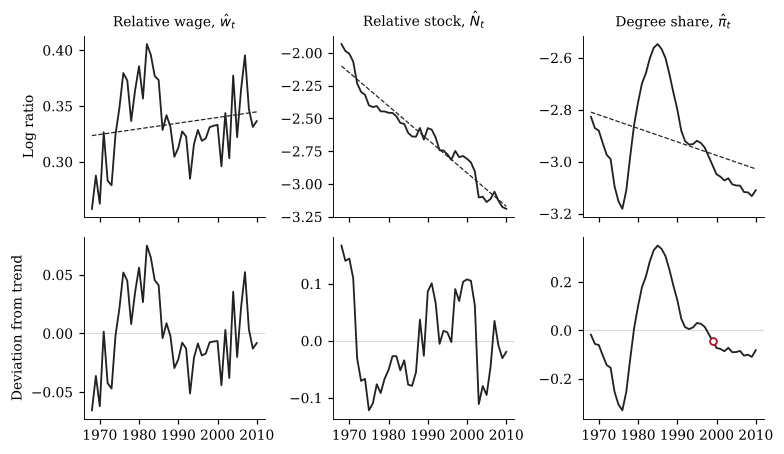

In [6]:
titles = {'w': r'Relative wage, $\hat w_t$', 'N': r'Relative stock, $\hat N_t$', 'pi': r'Degree share, $\hat\pi_t$'}
fig, ax = plt.subplots(2, 3, figsize=(7.2, 4.2), sharex=True)
for j, v in enumerate(['w', 'N', 'pi']):
    ax[0, j].plot(df.year, df[v], color=INK, lw=1.2)
    ax[0, j].plot(df.year, df[v] - Y[v], color=INK, lw=0.8, ls='--')          # the fitted trend
    ax[0, j].set_title(titles[v], fontsize=9)
    ax[1, j].axhline(0, color='#d9d9d9', lw=0.8)
    ax[1, j].plot(Y.year, Y[v], color=INK, lw=1.2)
    ax[1, j].set_xticks([1970, 1980, 1990, 2000, 2010])
y99 = Y.year == 1999
ax[1, 2].plot(Y.year[y99], Y.pi[y99], 'o', ms=4.5, mfc='white', mec=RED, mew=1.2)
ax[0, 0].set_ylabel('Log ratio'); ax[1, 0].set_ylabel('Deviation from trend')
fig.tight_layout(); fig.savefig(FIGS + 'fig_data_series.pdf')

### 1.5 Facts about measurement error and the stock

These numbers motivate the measurement-error specification in Section 4.1 and give an outside benchmark for $\lambda$ (Section 4.2).

In [7]:
print(f'engineers in the CPS sample per year: {df.n_eng_obs.min()} to {df.n_eng_obs.max()}')
jump = np.diff(np.log(df.stock_eng.values))
print(f'change in the measured stock of engineers in 2003: {100 * jump[df.year.values[1:] == 2003][0]:.1f} log points')
grad_ratio = (df.eng_deg / df.stock_eng).mean()
print(f'average ratio of engineering degrees to engineers: {grad_ratio:.3f}  ->  accounting lambda = {1 - grad_ratio:.3f}')

engineers in the CPS sample per year: 611 to 1409
change in the measured stock of engineers in 2003: -17.7 log points
average ratio of engineering degrees to engineers: 0.041  ->  accounting lambda = 0.959


## 2. Solving the model

### 2.1 Parameters

The model has 14 free parameters (equation (24)). The dictionary `th0` holds simple starting values for the estimation; we also use it to test the functions below.

In [8]:
PARAMS = ['f2', 'd', 'lam',                       # demand slope, enrollment cost, share of incumbents
          'a1_th', 'a2_th', 'sig_th',             # demand shock AR(2)
          'a1_psi', 'a2_psi', 'sig_psi',          # preference shock AR(2)
          'sig_w', 'D_w', 'sig_N', 'D_N', 'sig_pi']   # measurement errors

th0 = dict(f2=0.3, d=0.05, lam=0.96, a1_th=0.8, a2_th=0.0, sig_th=0.01,
           a1_psi=1.3, a2_psi=-0.4, sig_psi=0.05, sig_w=0.02, D_w=0.0, sig_N=0.05, D_N=0.5, sig_pi=0.01)

def ar2_roots(a1, a2):
    """Roots of z^2 = a1 z + a2, their largest modulus, and the period of the cycle (nan if the roots are real)."""
    r = np.roots([1, -a1, -a2])
    period = 2 * np.pi / abs(np.angle(r[0])) if abs(r[0].imag) > 1e-10 else np.nan
    return r, np.abs(r).max(), period

### 2.2 The linear-quadratic planning problem

State and control (Section 2.2):
$$X_t=(N_t,\,n_{t-1},\,n_{t-2},\,n_{t-3},\,n_{t-4},\,\theta_t,\,\psi_t,\,\theta_{t-1},\,\psi_{t-1})',\qquad u_t=n_t .$$
The constraints are $X_{t+1}=AX_t+Bu_t+C\varepsilon_{t+1}$ and the period return is $X_t'RX_t+Qu_t^2+2u_tWX_t$ (equation (12) and Appendix A.5).

In [9]:
STATE = ['N', 'n1', 'n2', 'n3', 'n4', 'th', 'psi', 'th_1', 'psi_1']

def lq_matrices(th):
    lam, f2, d = th['lam'], th['f2'], th['d']
    A = np.zeros((9, 9))
    A[0, 0], A[0, 3] = lam, 1 - lam                  # N_{t+1} = lam N_t + (1 - lam) n_{t-3}
    A[2, 1] = A[3, 2] = A[4, 3] = 1.0                # shift the cohorts still in school
    A[5, 5], A[5, 7] = th['a1_th'], th['a2_th']      # theta_{t+1} = a1 theta_t + a2 theta_{t-1}
    A[6, 6], A[6, 8] = th['a1_psi'], th['a2_psi']    # psi_{t+1}   = a1 psi_t   + a2 psi_{t-1}
    A[7, 5] = A[8, 6] = 1.0                          # keep last year's shocks
    B = np.zeros((9, 1)); B[1, 0] = 1.0              # n_t becomes next year's n_{t-1}
    C = np.zeros((9, 2)); C[5, 0], C[6, 1] = th['sig_th'], th['sig_psi']
    R = np.zeros((9, 9)); R[0, 0] = -f2 / 2; R[0, 5] = R[5, 0] = 0.5     # theta N - (f2/2) N^2
    Q = np.array([[-d / 2]])                                             # -(d/2) n^2
    W = np.zeros((1, 9)); W[0, 6] = d / 2                                # 2 n (d/2) psi = d psi n
    return A, B, C, R, Q, W

pd.DataFrame(lq_matrices(th0)[0], index=STATE, columns=STATE).round(2)

,N,n1,n2,n3,n4,th,psi,th_1,psi_1
N,0.96,0.0,0.0,0.04,0.0,0.0,0.0,0.0,0.0
n1,0.00,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0
n2,0.00,1.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0
n3,0.00,0.0,1.0,0.00,0.0,0.0,0.0,0.0,0.0
n4,0.00,0.0,0.0,1.00,0.0,0.0,0.0,0.0,0.0
th,0.00,0.0,0.0,0.00,0.0,0.8,0.0,0.0,0.0
psi,0.00,0.0,0.0,0.00,0.0,0.0,1.3,0.0,-0.4
th_1,0.00,0.0,0.0,0.00,0.0,1.0,0.0,0.0,0.0
psi_1,0.00,0.0,0.0,0.00,0.0,0.0,1.0,0.0,0.0


### 2.3 Riccati equation, decision rule, and law of motion

The value function is $v(X)=X'PX+c$, where $P$ solves the Riccati equation (15). The decision rule is $u_t=-FX_t$ with $F=(Q+\beta B'PB)^{-1}(W+\beta B'PA)$, and the equilibrium law of motion is $X_{t+1}=MX_t+C\varepsilon_{t+1}$, $M=A-BF$.

We solve the Riccati equation with SciPy's solver for discrete algebraic Riccati equations. SciPy minimizes an undiscounted cost, so we (i) multiply $A$ and $B$ by $\sqrt\beta$ and (ii) flip the signs of $R$, $Q$, $W$ (maximizing a return = minimizing its negative).

The observation matrix $G$ picks out the wage $w_t=-f_2N_t+\theta_t$, the stock $N_t$, and the degree share $\pi_t=n_{t-4}$.

In [10]:
def solve_riccati(A, B, R, Q, W, beta=BETA):
    s = np.sqrt(beta)
    return -sl.solve_discrete_are(s * A, s * B, -R, -Q, s=-W.T)

def observation_matrix(f2):
    G = np.zeros((3, 9))
    G[0, 0], G[0, 5] = -f2, 1.0      # wage
    G[1, 0] = 1.0                    # stock
    G[2, 4] = 1.0                    # degree share = n_{t-4}
    return G

def solve_re(th):
    """Rational expectations: returns M, C, G, F with X_{t+1} = M X_t + C eps, y = G X, n_t = -F X_t."""
    A, B, C, R, Q, W = lq_matrices(th)
    P = solve_riccati(A, B, R, Q, W)
    F = np.linalg.solve(Q + BETA * B.T @ P @ B, W + BETA * B.T @ P @ A)
    return A - B @ F, C, observation_matrix(th['f2']), F

M, C, G, F = solve_re(th0)
print('decision rule n_t = -F X_t:')
print(pd.Series(-F[0], index=STATE).round(4).to_string())
print('largest |eigenvalue| of M:', np.abs(np.linalg.eigvals(M)).max().round(4))

decision rule n_t = -F X_t:
N       -1.0386
n1      -0.0470
n2      -0.0451
n3      -0.0433
n4       0.0000
th       0.8859
psi      0.7086
th_1     0.0000
psi_1    0.1022
largest |eigenvalue| of M: 0.913


**Two checks.** (a) Iterating on the Riccati equation from $P=0$ gives the same $P$ as the direct solver. (b) Proposition 1: the planner's decision rule coincides with the household's enrollment equation $n_t=\frac{1-\lambda}{d}V_t+\psi_t$, where by equation (17) $V_t=\beta^4G_wM^4(I-\beta\lambda M)^{-1}X_t$.

In [11]:
def riccati_iterate(A, B, R, Q, W, beta=BETA, tol=1e-12, maxit=20000):
    P = np.zeros_like(R)
    for it in range(maxit):
        K = W + beta * B.T @ P @ A
        P_new = R + beta * A.T @ P @ A - K.T @ np.linalg.solve(Q + beta * B.T @ P @ B, K)
        if np.abs(P_new - P).max() < tol:
            return P_new
        P = P_new
    raise RuntimeError('no convergence')

def check_solution(th):
    A, B, C, R, Q, W = lq_matrices(th)
    gap_P = np.abs(riccati_iterate(A, B, R, Q, W) - solve_riccati(A, B, R, Q, W)).max()
    M, C, G, F = solve_re(th)
    V_row = BETA**4 * G[0] @ np.linalg.matrix_power(M, 4) @ np.linalg.inv(np.eye(9) - BETA * th['lam'] * M)
    household_rule = (1 - th['lam']) / th['d'] * V_row + np.eye(9)[6]          # (1-lam)/d V_t + psi_t
    gap_rule = np.abs(-F[0] - household_rule).max()
    print(f'(a) max |P_iterated - P_direct| = {gap_P:.1e}    (b) max |planner rule - household rule| = {gap_rule:.1e}')

check_solution(th0)

(a) max |P_iterated - P_direct| = 3.3e-12    (b) max |planner rule - household rule| = 5.9e-15


### 2.4 Cobweb expectations

Under cobweb expectations students expect today's wage to last, and enrollment is $n_t=\eta w_t+\psi_t=-\eta f_2N_t+\eta\theta_t+\psi_t$ (equation (10)). There is no planning problem to solve: we plug this rule into the same $A$, $B$, $C$. The cobweb model has $\eta$ in place of $d$.

In [12]:
def solve_cobweb(th):
    A, B, C, _, _, _ = lq_matrices({**th, 'd': 1.0})      # d plays no role here
    K = np.zeros((1, 9))
    K[0, 0], K[0, 5], K[0, 6] = -th['eta'] * th['f2'], th['eta'], 1.0
    return A + B @ K, C, observation_matrix(th['f2']), -K   # same format as solve_re (n_t = -F X_t)

## 3. The likelihood

### 3.1 State-space form with measurement error

Each observation equals its model counterpart plus an AR(1) measurement error (equation (20)):
$$y_t=GX_t+v_t,\qquad v^x_{t+1}=D_xv^x_t+\sigma_xe^x_{t+1},\qquad D_\pi=0 .$$
Stacking $s_t=(X_t',v_t')'$ gives $s_{t+1}=\mathcal M s_t+\mathcal C\epsilon_{t+1}$ and $y_t=\mathcal G s_t$ (equation (21), Appendix B.1).

In [13]:
def state_space(th, solve=solve_re):
    M, C, G, F = solve(th)
    D = np.diag([th['D_w'], th['D_N'], 0.0])
    Mf = sl.block_diag(M, D)
    Cf = sl.block_diag(C, np.diag([th['sig_w'], th['sig_N'], th['sig_pi']]))
    Gf = np.hstack([G, np.eye(3)])
    return Mf, Cf, Gf

### 3.2 The Kalman filter (Algorithm 1)

Start from the stationary distribution: $\hat s_1=0$ and $\Sigma_1=\mathcal M\Sigma_1\mathcal M'+\mathcal C\mathcal C'$. Then for $t=1,\dots,T$:

- innovation $a_t=y_t-\mathcal G\hat s_t$ with covariance $\Omega_t=\mathcal G\Sigma_t\mathcal G'$;
- add $-\tfrac32\log2\pi-\tfrac12\log\det\Omega_t-\tfrac12a_t'\Omega_t^{-1}a_t$ to $\log L$ (equation (23));
- gain $K_t=\mathcal M\Sigma_t\mathcal G'\Omega_t^{-1}$, update $\hat s_{t+1}=\mathcal M\hat s_t+K_ta_t$ and $\Sigma_{t+1}=(\mathcal M-K_t\mathcal G)\Sigma_t(\mathcal M-K_t\mathcal G)'+\mathcal C\mathcal C'$.

If the model cannot be solved or is not stationary, the function returns $-10^{10}$.

In [14]:
BAD = -1e10

def loglik(th, Ydata=Yobs, solve=solve_re):
    try:
        Mf, Cf, Gf = state_space(th, solve)
    except (np.linalg.LinAlgError, ValueError):
        return BAD
    if not np.all(np.isfinite(Mf)) or np.abs(np.linalg.eigvals(Mf)).max() >= 1:
        return BAD
    S = sl.solve_discrete_lyapunov(Mf, Cf @ Cf.T)           # Sigma_1
    s_hat = np.zeros(Mf.shape[0])
    logL = 0.0
    for y in Ydata:
        a = y - Gf @ s_hat                                     # innovation
        Om = Gf @ S @ Gf.T                                     # its covariance
        sign, logdet = np.linalg.slogdet(Om)
        if sign <= 0:
            return BAD
        Om_inv = np.linalg.inv(Om)
        logL += -1.5 * np.log(2 * np.pi) - 0.5 * logdet - 0.5 * a @ Om_inv @ a
        K = Mf @ S @ Gf.T @ Om_inv                             # Kalman gain
        s_hat = Mf @ s_hat + K @ a
        S = (Mf - K @ Gf) @ S @ (Mf - K @ Gf).T + Cf @ Cf.T
    return logL

print(f'log L at the starting values: {loglik(th0):.2f}')

log L at the starting values: 242.48


## 4. Estimation

### 4.1 Reparametrization and the optimizer

To keep every trial point inside the parameter space, the optimizer works with an unconstrained vector $z$:

| parameter | transformation |
|---|---|
| $f_2$, $d$, $\eta$, all standard deviations | $\exp(z)$ |
| $\lambda$ | $1/(1+e^{-z})$ |
| $a_2$, $D_w$, $D_N$ | $\tanh(z)$ |
| $a_1$ | $(1-a_2)\tanh(z)$, so that $(a_1,a_2)$ is always stationary |

We minimize $-\log L$ with Nelder–Mead, then BFGS, then Nelder–Mead again, and keep the best point.

In [15]:
TRANSFORMS = {k: (np.exp, np.log) for k in ['f2', 'd', 'eta', 'sig_th', 'sig_psi', 'sig_w', 'sig_N', 'sig_pi']}
TRANSFORMS.update({k: (np.tanh, np.arctanh) for k in ['a1_th', 'a2_th', 'a1_psi', 'a2_psi', 'D_w', 'D_N']})
TRANSFORMS['lam'] = (lambda z: 1 / (1 + np.exp(-z)), lambda v: np.log(v / (1 - v)))
SCALED = {'a1_th': 'a2_th', 'a1_psi': 'a2_psi'}               # a1 = (1 - a2) tanh(z)

def to_theta(z, free, fixed):
    th = {**fixed, **{k: TRANSFORMS[k][0](zi) for k, zi in zip(free, z)}}
    for a1, a2 in SCALED.items():
        if a1 in free:
            th[a1] = (1 - th[a2]) * th[a1]
    return th

def to_z(th, free):
    return np.array([TRANSFORMS[k][1](th[k] / (1 - th[SCALED[k]]) if k in SCALED else th[k]) for k in free])

def fit(free, fixed, start, solve=solve_re, quick=False):
    """Maximize log L over the parameters in `free`, holding `fixed` constant. Returns (log L, parameters)."""
    def nll(z):
        v = -loglik(to_theta(z, free, fixed), Yobs, solve)
        return v if np.isfinite(v) else -BAD
    z = to_z(start, free)
    if not quick:
        z = so.minimize(nll, z, method='Nelder-Mead', options=dict(maxfev=8000, xatol=1e-8, fatol=1e-9)).x
    r = so.minimize(nll, z, method='BFGS')
    if not quick:
        r2 = so.minimize(nll, r.x, method='Nelder-Mead', options=dict(maxfev=3000, xatol=1e-10, fatol=1e-11))
        r = r2 if r2.fun < r.fun else r
    return -r.fun, to_theta(r.x, free, fixed)

### 4.2 Maximum likelihood estimates

In [16]:
logL_hat, th_hat = cached('mle', lambda: fit(PARAMS, {}, th0))       # about 3 minutes the first time
print(f'maximized log likelihood: {logL_hat:.2f}')
pd.Series(th_hat)[PARAMS].round(4)

maximized log likelihood: 260.47


f2         0.6376
d          0.0753
lam        0.9554
a1_th      0.6972
a2_th      0.1761
sig_th     0.0137
a1_psi     1.7346
a2_psi    -0.8153
sig_psi    0.0329
sig_w      0.0180
D_w       -0.0982
sig_N      0.0492
D_N        0.7291
sig_pi     0.0000
dtype: float64

**Different starting values.** We restart the optimizer from eight combinations of starting values for the two autoregressions and the enrollment cost $d$.

In [17]:
def multistart():
    rows = []
    for a_th in [(0.8, 0.0), (1.6, -0.65)]:
        for a_psi in [(1.3, -0.4), (1.0, -0.2)]:
            for d0 in [0.05, 0.5]:
                start = {**th0, 'a1_th': a_th[0], 'a2_th': a_th[1], 'a1_psi': a_psi[0], 'a2_psi': a_psi[1], 'd': d0}
                ll, th = fit(PARAMS, {}, start)
                rows.append({'a_theta start': a_th, 'a_psi start': a_psi, 'd start': d0, 'log L': ll,
                             'f2': th['f2'], 'd': th['d'], 'a1_psi': th['a1_psi'], 'a2_psi': th['a2_psi']})
    return pd.DataFrame(rows)

starts_re = cached('multistart_re', multistart)
same = (starts_re['log L'] - logL_hat).abs() < 0.01
print(f'{same.sum()} of {len(starts_re)} starting values reach the maximum log L = {logL_hat:.2f}')
starts_re.round(3)

7 of 8 starting values reach the maximum log L = 260.47


,a_theta start,a_psi start,d start,log L,f2,d,a1_psi,a2_psi
0,"(0.8, 0.0)","(1.3, -0.4)",0.05,260.475,0.638,0.075,1.735,-0.815
1,"(0.8, 0.0)","(1.3, -0.4)",0.50,260.475,0.638,0.075,1.735,-0.815
2,"(0.8, 0.0)","(1.0, -0.2)",0.05,260.475,0.638,0.075,1.735,-0.815
3,"(0.8, 0.0)","(1.0, -0.2)",0.50,260.475,0.638,0.075,1.735,-0.815
4,"(1.6, -0.65)","(1.3, -0.4)",0.05,260.475,0.638,0.075,1.735,-0.815
5,"(1.6, -0.65)","(1.3, -0.4)",0.50,259.447,1.911,0.032,1.748,-0.837
6,"(1.6, -0.65)","(1.0, -0.2)",0.05,260.475,0.638,0.075,1.735,-0.815
7,"(1.6, -0.65)","(1.0, -0.2)",0.50,260.475,0.638,0.075,1.735,-0.815


### 4.3 Standard errors

Standard errors come from the inverse of the numerical Hessian of $\log L$ with respect to the original parameters. $\hat\sigma_\pi$ is estimated at its boundary value 0 (a Heywood case), so it is held at 0 and gets no standard error.

In [18]:
def hessian(f, x, rel=1e-4):
    h = rel * np.maximum(np.abs(x), 1e-2)
    k = len(x); H = np.zeros((k, k))
    for i in range(k):
        for j in range(i, k):
            ei, ej = np.eye(k)[i] * h[i], np.eye(k)[j] * h[j]
            H[i, j] = H[j, i] = (f(x + ei + ej) - f(x + ei - ej) - f(x - ei + ej) + f(x - ei - ej)) / (4 * h[i] * h[j])
    return H

def std_errors(th, params, solve=solve_re, tol=1e-4):
    at_bound = [k for k in params if k.startswith('sig') and th[k] < tol]     # standard deviations at 0
    free = [k for k in params if k not in at_bound]
    fixed = {k: 0.0 for k in at_bound}
    v = np.array([th[k] for k in free])
    V = np.linalg.inv(-hessian(lambda u: loglik({**fixed, **dict(zip(free, u))}, Yobs, solve), v))
    return dict(zip(free, np.sqrt(np.diag(V)))), free, v, V

se, free_se, v_hat, V_hat = std_errors(th_hat, PARAMS)
print('held at the boundary:', [k for k in PARAMS if k not in free_se])

held at the boundary: ['sig_pi']


### 4.4 Profile likelihood intervals

A standard error describes only the curvature of $\log L$ at its peak. The profile likelihood shows the whole shape: fix one parameter at a grid point $x$, re-maximize over the other 13, and compute $LR(x)=2[\log L(\hat\Theta)-\log L_p(x)]$ (equation (25)). The 95 percent interval collects the $x$ with $LR(x)\le3.84$. Each re-maximization starts from the solution at the neighbouring grid point, and the grid is swept twice to avoid getting stuck.

In [19]:
PAIR = {'a1_th': 'a2_th', 'a1_psi': 'a2_psi'}
sigmoid = lambda z: 1 / (1 + np.exp(-z))
logit = lambda u: np.log(u / (1 - u))

def profile_grid(k, n=13):
    est = th_hat[k]
    if k == 'sig_pi':
        return np.array([0.0, 0.002, 0.005, 0.01, 0.015, 0.02, 0.03])
    if k in ['f2', 'd', 'sig_th', 'sig_psi', 'sig_w', 'sig_N']:          # positive: equally spaced in logs
        g = est * np.exp(3 * se[k] / est * np.linspace(-1, 1, n))
    else:
        lo, hi = {'lam': (0.5, 0.995), 'a1_th': (-1.98, 1.98), 'a1_psi': (-1.98, 1.98)}.get(k, (-0.98, 0.98))
        g = np.clip(est + 3 * se[k] * np.linspace(-1, 1, n), lo, hi)
    return np.unique(np.r_[g, est])

def profile(k):
    grid = profile_grid(k)
    free = [p for p in PARAMS if p != k]
    best_ll = np.full(len(grid), -np.inf); sols = [None] * len(grid)
    saved = dict(TRANSFORMS)

    def step(i, start):
        x = grid[i]; start = {**start, k: x}
        if k in PAIR:          # a1 fixed at x: a2 must stay in (-1, 1 - |x|) for stationarity
            p, top = PAIR[k], 1 - abs(x)
            TRANSFORMS[p] = (lambda z, t=top: -1 + (1 + t) * sigmoid(z), lambda v, t=top: logit((v + 1) / (1 + t)))
            start[p] = np.clip(start[p], -1 + 1e-3, top - 1e-3)
        elif k in PAIR.values():   # a2 fixed at x: a1 = (1 - x) tanh(z) keeps (a1, a2) stationary
            a1 = next(q for q in PAIR if PAIR[q] == k)
            start[a1] = np.clip(start[a1], -(1 - x) * 0.999, (1 - x) * 0.999)
        ll, th = fit(free, {k: x}, start, quick=True)
        TRANSFORMS.update(saved)
        if ll > best_ll[i]:
            best_ll[i], sols[i] = ll, th

    i0 = int(np.argmin(np.abs(grid - th_hat[k])))
    for order in (range(i0, len(grid)), range(i0, -1, -1)):              # sweep 1: outward from the estimate
        prev = th_hat
        for i in order:
            step(i, prev); prev = sols[i]
    for order in (range(1, len(grid)), range(len(grid) - 2, -1, -1)):    # sweep 2: once in each direction
        for i in order:
            step(i, sols[i - 1] if order.step == 1 else sols[i + 1])
    return grid, 2 * (max(logL_hat, best_ll.max()) - best_ll)

profiles = {k: cached('profile_' + k, lambda k=k: profile(k)) for k in PARAMS}   # about 30-45 minutes the first time

def profile_interval(grid, lr, crit=3.84):
    """Interpolate where LR crosses 3.84 on each side; if it never does, report the grid edge with < or >."""
    i0 = int(np.argmin(lr)); lo = hi = None
    for i in range(i0, 0, -1):
        if lr[i - 1] > crit:
            lo = np.interp(crit, [lr[i], lr[i - 1]], [grid[i], grid[i - 1]]); break
    for i in range(i0, len(grid) - 1):
        if lr[i + 1] > crit:
            hi = np.interp(crit, [lr[i], lr[i + 1]], [grid[i], grid[i + 1]]); break
    return (f'{lo:.3f}' if lo is not None else f'< {grid[0]:.3f}'), (f'{hi:.3f}' if hi is not None else f'> {grid[-1]:.3f}')

**Figure 2.** Profile likelihood for nine parameters. Dashed line: the 5 percent critical value 3.84. Dotted line: the estimate.

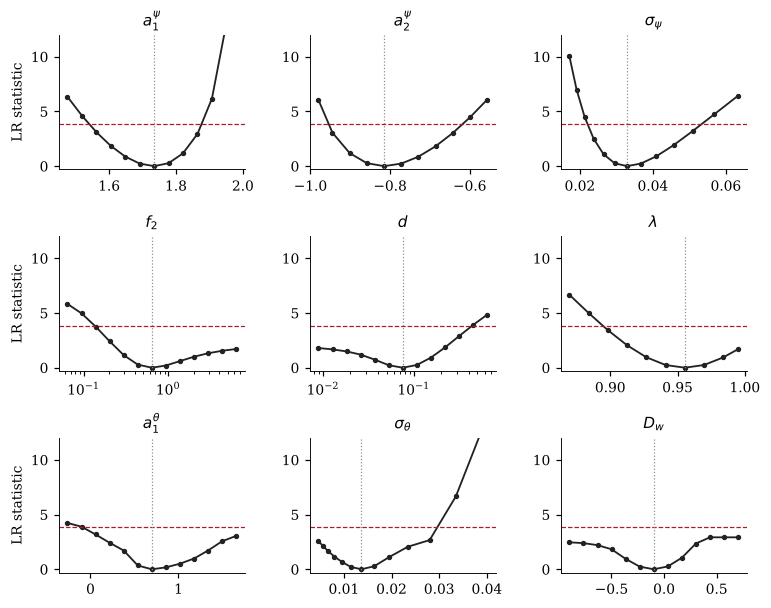

In [20]:
labels = {'a1_psi': r'$a^{\psi}_1$', 'a2_psi': r'$a^{\psi}_2$', 'sig_psi': r'$\sigma_{\psi}$',
          'f2': r'$f_2$', 'd': r'$d$', 'lam': r'$\lambda$',
          'a1_th': r'$a^{\theta}_1$', 'sig_th': r'$\sigma_{\theta}$', 'D_w': r'$D_w$'}
fig, axs = plt.subplots(3, 3, figsize=(7.2, 5.6))
for a, k in zip(axs.flat, labels):
    g, lr = profiles[k]
    a.plot(g, lr, color=INK, lw=1.2, marker='o', ms=2.5)
    a.axhline(3.84, color=RED, ls='--', lw=0.8); a.axvline(th_hat[k], color=GREY, ls=':', lw=0.8)
    a.set_ylim(-0.3, 12); a.set_title(labels[k], fontsize=10)
    if k in ('f2', 'd'):
        a.set_xscale('log')
for r in range(3):
    axs[r, 0].set_ylabel('LR statistic')
fig.tight_layout(); fig.savefig(FIGS + 'fig_profile.pdf')

### 4.5 Table 1: parameter estimates

The implied quantities are the demand elasticity $1/f_2$, the coefficient on career value $(1-\lambda)/d$, and the long-run entry elasticity $\eta^{LR}=\frac{(1-\lambda)\beta^4}{d(1-\beta\lambda)}$ (equation (9)); their standard errors use the delta method.

In [21]:
def implied(v):
    p = dict(zip(free_se, v)); slope = (1 - p['lam']) / p['d']
    return np.array([1 / p['f2'], slope, slope * BETA**4 / (1 - BETA * p['lam'])])

J = np.zeros((3, len(v_hat)))                                     # numerical Jacobian for the delta method
for i in range(len(v_hat)):
    e = np.zeros(len(v_hat)); e[i] = 1e-6 * max(abs(v_hat[i]), 1e-2)
    J[:, i] = (implied(v_hat + e) - implied(v_hat - e)) / (2 * e[i])
imp, imp_se = implied(v_hat), np.sqrt(np.diag(J @ V_hat @ J.T))

table1 = pd.DataFrame([[th_hat[k], se.get(k, np.nan), *profile_interval(*profiles[k])] for k in PARAMS],
                      index=PARAMS, columns=['estimate', 's.e.', 'profile lower', 'profile upper'])
table1.loc['sig_pi', 'profile lower'] = '0 (boundary)'
for name, val, s in zip(['1/f2 (demand elasticity)', '(1-lam)/d (coefficient on V)', 'eta_LR (long-run entry elasticity)'],
                        imp, imp_se):
    table1.loc[name] = [val, s, '', '']
print(f'maximized log likelihood: {logL_hat:.2f}')
table1.round(4)

maximized log likelihood: 260.47


,estimate,s.e.,profile lower,profile upper
f2,0.6376,0.4874,0.135,> 6.318
d,0.0753,0.0537,< 0.009,0.439
lam,0.9554,0.0286,0.895,> 0.995
a1_th,0.6972,0.3194,-0.090,> 1.656
a2_th,0.1761,0.3243,< -0.797,0.646
sig_th,0.0137,0.0049,< 0.005,0.030
a1_psi,1.7346,0.0864,1.541,1.876
a2_psi,-0.8153,0.0863,-0.954,-0.618
sig_psi,0.0329,0.0072,0.022,0.053
sig_w,0.0180,0.0038,< 0.010,0.026


**Numbers used in the text of Section 4.2.**

In [22]:
mult = BETA**4 / (1 - BETA * th_hat['lam'])
print(f'permanent 1% wage increase raises V by beta^4/(1-beta*lam) = {mult:.2f} points; '
      f'long-run entry elasticity = {imp[1]:.2f} x {mult:.2f} = {imp[2]:.2f}')
print(f'demand elasticity bound implied by the lower profile bound of f2: 1/{float(table1.loc["f2", "profile lower"]):.3f} '
      f'= {1 / float(table1.loc["f2", "profile lower"]):.1f}')
print(f'lambda: estimate {th_hat["lam"]:.3f}, accounting benchmark {1 - grad_ratio:.3f}')
for s, name in [('th', 'demand'), ('psi', 'preference')]:
    r, mod, per = ar2_roots(th_hat['a1_' + s], th_hat['a2_' + s])
    print(f'{name} shock roots: {np.round(r, 3)}, modulus {mod:.2f}' + (f', period {per:.1f} years' if np.isfinite(per) else ' (real)'))
print(f'stock measurement error: s.d. {th_hat["sig_N"]:.3f}, persistence {th_hat["D_N"]:.2f}, '
      f'half-life {np.log(0.5) / np.log(th_hat["D_N"]):.1f} years; s.d. of detrended stock {Y.N.std(ddof=0):.3f}')

permanent 1% wage increase raises V by beta^4/(1-beta*lam) = 10.26 points; long-run entry elasticity = 0.59 x 10.26 = 6.07
demand elasticity bound implied by the lower profile bound of f2: 1/0.135 = 7.4
lambda: estimate 0.955, accounting benchmark 0.959
demand shock roots: [ 0.894 -0.197], modulus 0.89 (real)
preference shock roots: [0.867+0.251j 0.867-0.251j], modulus 0.90, period 22.3 years
stock measurement error: s.d. 0.049, persistence 0.73, half-life 2.2 years; s.d. of detrended stock 0.079


### 4.6 Are the roots of the preference shock complex?

We restrict both shocks to real roots, $1-a_1L-a_2L^2=(1-r_1L)(1-r_2L)$ with $r_1,r_2\in(-1,1)$, i.e. $a_1=r_1+r_2$ and $a_2=-r_1r_2$, re-estimate from five starting values, and compute the likelihood ratio statistic.

In [23]:
OTHER = [p for p in PARAMS if p not in ('a1_th', 'a2_th', 'a1_psi', 'a2_psi')]

def unpack_real(z):
    th = {k: TRANSFORMS[k][0](zi) for k, zi in zip(OTHER, z[:len(OTHER)])}
    r = np.tanh(z[len(OTHER):])                                  # four real roots in (-1, 1)
    th['a1_th'], th['a2_th'] = r[0] + r[1], -r[0] * r[1]
    th['a1_psi'], th['a2_psi'] = r[2] + r[3], -r[2] * r[3]
    return th

def fit_real(roots_th, roots_psi):
    nll = lambda z: (lambda v: v if np.isfinite(v) else -BAD)(-loglik(unpack_real(z)))
    z = np.r_[[TRANSFORMS[k][1](th_hat[k]) for k in OTHER], np.arctanh(np.r_[roots_th, roots_psi])]
    r = so.minimize(nll, z, method='Nelder-Mead', options=dict(maxfev=20000, xatol=1e-8, fatol=1e-9))
    r = so.minimize(nll, r.x, method='BFGS')
    r2 = so.minimize(nll, r.x, method='Nelder-Mead', options=dict(maxfev=5000, xatol=1e-10, fatol=1e-11))
    r = r2 if r2.fun < r.fun else r
    return -r.fun, unpack_real(r.x)

real_fits = cached('real_roots', lambda: [fit_real((0.89, -0.2), psi0)
                                          for psi0 in [(0.8, 0.8), (0.9, 0.5), (0.95, 0.7), (0.85, 0.85), (0.6, 0.3)]])
for ll, th in real_fits:
    print(f'log L = {ll:.2f}   preference-shock roots {np.round(ar2_roots(th["a1_psi"], th["a2_psi"])[0], 3)}')
ll_real = max(ll for ll, _ in real_fits)
print(f'\nLR = 2 x ({logL_hat:.2f} - {ll_real:.2f}) = {2 * (logL_hat - ll_real):.2f};  '
      f'5% critical values: 3.84 (chi2 with 1 d.f.), 2.71 (50:50 mixture of chi2_0 and chi2_1)')

log L = 258.11   preference-shock roots [0.796 0.796]
log L = 258.11   preference-shock roots [0.796 0.796]
log L = 258.11   preference-shock roots [0.796 0.796]
log L = 258.11   preference-shock roots [0.796 0.796]
log L = 258.11   preference-shock roots [0.796 0.796]

LR = 2 x (260.47 - 258.11) = 4.72;  5% critical values: 3.84 (chi2 with 1 d.f.), 2.71 (50:50 mixture of chi2_0 and chi2_1)


### 4.7 The term dropped from the stock equation (Appendix A.1)

The model's stock equation is for the *relative* stock. We get it by log-linearizing the stock equation of engineers, doing the same for all college graduates, and subtracting. If the two groups had the same $\lambda$, the difference would be exactly equation (5). They do not, so the difference contains an extra term,
$$(\lambda-\lambda^c)\,(\hat\ell^c_t-\hat s^c_{t-3}),$$
which the model drops. Here we check that this term is small.

1. Since $1-\lambda$ is roughly the share of new graduates in the stock, we estimate each group's $\lambda$ as $1-$ (average of graduates / stock).
2. $\hat\ell^c_t$ is the log stock of college graduates. $\hat s^c_{t-3}$ is the log number of students who entered college in year $t-3$; entrants are not observed, so we use the degrees they receive four years later, in year $t+1$.
3. We detrend, multiply by $\lambda-\lambda^c$, and compare the standard deviation with that of the detrended relative stock $\tilde N_t$.

In [24]:
lam_eng = 1 - grad_ratio                                   # engineers
lam_col = 1 - (df.tot_deg / df.stock_coll).mean()          # all college graduates
cps_y, nsf_y = cps.set_index('year'), nsf.set_index('year')
yrs = np.arange(FIRST, LAST)                               # t = 1968..2009 (degrees in t+1 are needed)
log_stock = np.log(cps_y.loc[yrs, 'stock_coll'].values)    # log stock of college graduates in year t
log_entry = np.log(nsf_y.loc[yrs + 1, 'tot_deg'].values)   # entrants of year t-3 = graduates of year t+1
tt = np.arange(len(yrs)); x = log_stock - log_entry
term = x - np.polyval(np.polyfit(tt, x, 1), tt)            # detrended
print(f'lambda: engineers {lam_eng:.4f}, all college graduates {lam_col:.4f}')
print(f's.d. of the dropped term {np.std((lam_eng - lam_col) * term):.4f}  vs  s.d. of the detrended stock {Y.N.std(ddof=0):.4f}')

lambda: engineers 0.9587, all college graduates 0.9425
s.d. of the dropped term 0.0022  vs  s.d. of the detrended stock 0.0787


## 5. Model fit (Table 2)

**Population moments.** The stationary variance of the state solves $\Sigma=\mathcal M\Sigma\mathcal M'+\mathcal C\mathcal C'$, and the autocovariances are $\Gamma_k=\mathcal G\mathcal M^k\Sigma\mathcal G'$ (Appendix C).

**Simulated samples.** Population moments describe an infinitely long, undetrended sample. To compare like with like, we draw 1,000 samples of 43 years from the estimated model (with measurement error), detrend each one exactly as the data, and compute the same statistics.

In [25]:
def autocov(th, kmax, solve=solve_re):
    Mf, Cf, Gf = state_space(th, solve)
    S = sl.solve_discrete_lyapunov(Mf, Cf @ Cf.T)
    return [Gf @ np.linalg.matrix_power(Mf, k) @ S @ Gf.T for k in range(kmax + 1)]

def lead_corr(x, y, k):
    """corr(x_t, y_{t+k})"""
    return np.corrcoef(x[:len(x) - k], y[k:])[0, 1] if k >= 0 else np.corrcoef(x[-k:], y[:len(y) + k])[0, 1]

def simulate(th, T, rng, solve=solve_re, burn=200):
    Mf, Cf, Gf = state_space(th, solve)
    s = np.zeros(Mf.shape[0]); out = []
    for _ in range(T + burn):
        s = Mf @ s + Cf @ rng.standard_normal(Cf.shape[1])
        out.append(Gf @ s)
    return np.array(out[burn:])

KS = np.arange(-8, 9)
def sample_stats(Ys):
    """3 standard deviations, 3 first-order autocorrelations, and corr(w_t, pi_{t+k}) for k = -8..8, after detrending."""
    tt = np.arange(len(Ys))
    Z = np.column_stack([x - np.polyval(np.polyfit(tt, x, 1), tt) for x in Ys.T])
    return np.r_[Z.std(axis=0), [np.corrcoef(z[:-1], z[1:])[0, 1] for z in Z.T],
                 [lead_corr(Z[:, 0], Z[:, 2], k) for k in KS]]

Gam = autocov(th_hat, 5)
sd_pop = np.sqrt(np.diag(Gam[0]))
pop = np.r_[sd_pop, np.diag(Gam[1]) / np.diag(Gam[0]), [Gam[k][2, 0] / (sd_pop[0] * sd_pop[2]) for k in (4, 5)]]

rng = np.random.default_rng(0)
sims_re = np.array([sample_stats(simulate(th_hat, len(Yobs), rng)) for _ in range(1000)])
stats_data = sample_stats(Yobs)

rows = [f's.d. {v}' for v in ['w', 'N', 'pi']] + [f'autocorr {v}' for v in ['w', 'N', 'pi']] + ['corr(w_t, pi_t+4)', 'corr(w_t, pi_t+5)']
pick = list(range(6)) + [6 + int(np.where(KS == k)[0][0]) for k in (4, 5)]
table2 = pd.DataFrame({'data': stats_data[pick], 'population': pop, 'median': np.median(sims_re, 0)[pick],
                       '5%': np.percentile(sims_re, 5, 0)[pick], '95%': np.percentile(sims_re, 95, 0)[pick]}, index=rows)
table2['inside 5-95%'] = (table2['data'] >= table2['5%']) & (table2['data'] <= table2['95%'])
table2.round(3)

,data,population,median,5%,95%,inside 5-95%
s.d. w,0.035,0.037,0.028,0.021,0.040,True
s.d. N,0.079,0.080,0.064,0.046,0.088,True
s.d. pi,0.169,0.140,0.118,0.065,0.195,True
autocorr w,0.569,0.653,0.431,0.016,0.725,True
autocorr N,0.765,0.778,0.657,0.408,0.816,True
autocorr pi,0.957,0.947,0.934,0.869,0.962,True
"corr(w_t, pi_t+4)",0.750,0.286,0.352,-0.118,0.691,False
"corr(w_t, pi_t+5)",0.763,0.319,0.365,-0.072,0.711,False


In [26]:
cc = slice(6, 6 + len(KS))
above = KS[stats_data[cc] > np.percentile(sims_re[:, cc], 95, 0)]
print('leads k at which the data lie above the 95th percentile of the simulated samples:', above.tolist())

leads k at which the data lie above the 95th percentile of the simulated samples: [3, 4, 5, 6]


## 6. Dynamics

### 6.1 Impulse responses (Figure 3)

A one-standard-deviation shock hits in year 0 and no further shocks occur: $X_h=M^hCe_j$, $w_h=G_wX_h$, $n_h=-FX_h$. Responses are in percent. For the preference shock we also split enrollment into the direct effect $\psi_h$ and the effect of expected wages $\frac{1-\lambda}{d}V_h=n_h-\psi_h$.

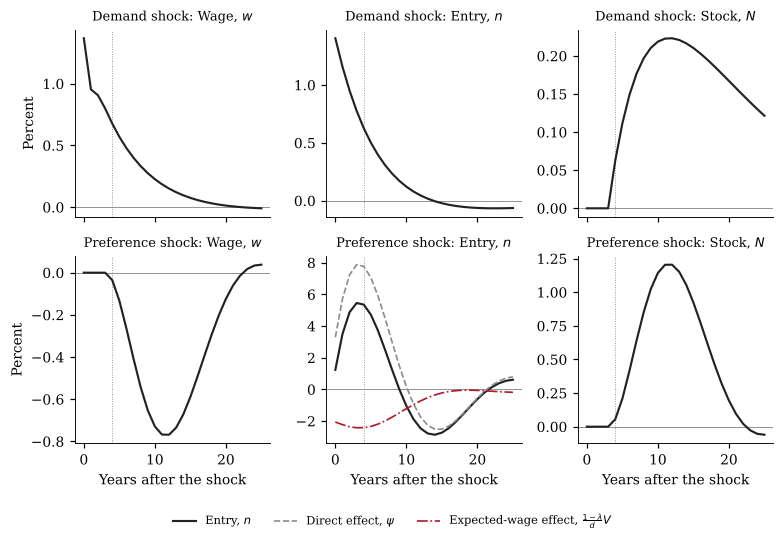

In [27]:
def impulse_response(th, j, solve=solve_re, H=26):
    """Columns: shock, entry n, stock N, wage w (percent). j = 0 demand shock, j = 1 preference shock."""
    M, C, G, F = solve(th)
    x = C[:, j].copy(); rows = []
    for h in range(H):
        rows.append([x[5 + j], -(F @ x)[0], x[0], G[0] @ x])
        x = M @ x
    return pd.DataFrame(100 * np.array(rows), columns=['shock', 'entry n', 'stock N', 'wage w'])

irf_d, irf_s = impulse_response(th_hat, 0), impulse_response(th_hat, 1)

fig, ax = plt.subplots(2, 3, figsize=(7.2, 4.9), sharex=True)
for r, (irf, name) in enumerate([(irf_d, 'Demand shock'), (irf_s, 'Preference shock')]):
    for c, (col, title) in enumerate([('wage w', 'Wage, $w$'), ('entry n', 'Entry, $n$'), ('stock N', 'Stock, $N$')]):
        a = ax[r, c]
        a.axhline(0, color=GREY, lw=0.6); a.axvline(4, color=GREY, lw=0.6, ls=':')
        a.plot(irf[col], color=INK, lw=1.4, label='Entry, $n$' if col == 'entry n' else None)
        if r == 1 and col == 'entry n':
            a.plot(irf['shock'], color=GREY, lw=1.1, ls='--', label=r'Direct effect, $\psi$')
            a.plot(irf['entry n'] - irf['shock'], color=RED, lw=1.1, ls='-.', label=r'Expected-wage effect, $\frac{1-\lambda}{d}V$')
        a.set_title(f'{name}: {title}', fontsize=8.5)
for a in ax[1]:
    a.set_xlabel('Years after the shock')
ax[0, 0].set_ylabel('Percent'); ax[1, 0].set_ylabel('Percent')
handles, labs = ax[1, 1].get_legend_handles_labels()
fig.legend(handles, labs, loc='lower center', ncol=3, fontsize=7.5, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(FIGS + 'fig_irf.pdf')

**Numbers used in Section 5.1.** For the demand shock, $\psi=0$, so career value can be read off the enrollment response: $V_0=n_0\,d/(1-\lambda)$. We compare it with the value $V$ would take if the same wage increase were permanent, $w_0\,\beta^4/(1-\beta\lambda)$.

In [28]:
lam, d = th_hat['lam'], th_hat['d']
w0, n0 = irf_d['wage w'][0], irf_d['entry n'][0]
V0 = n0 * d / (1 - lam)
V_perm = w0 * BETA**4 / (1 - BETA * lam)
half = next(h for h, v in enumerate(irf_d['wage w']) if v <= 0.5 * w0)
print(f'demand shock: wage {w0:.2f}%, entry {n0:.2f}% on impact; wage response halves after {half} years')
print(f'  career value rises by {V0:.1f} points; it would rise by {V_perm:.1f} points if the wage increase were permanent')
print(f'  entry {n0:.2f}% vs {(1 - lam) / d * V_perm:.1f}% under a permanent increase: ratio {n0 / ((1 - lam) / d * V_perm):.2f}')
psi0, ns0 = irf_s['shock'][0], irf_s['entry n'][0]
print(f'preference shock: shock {psi0:.2f}%, entry {ns0:.2f}% on impact ({ns0 / psi0:.0%} of the shock; '
      f'expected wages offset {1 - ns0 / psi0:.0%})')
print(f'  stock peaks at {irf_s["stock N"].max():.2f}% in year {irf_s["stock N"].idxmax()}; '
      f'wage trough {irf_s["wage w"].min():.2f}% in year {irf_s["wage w"].idxmin()}')
print(f'without new entry, a stock deviation halves in ln(0.5)/ln(lambda) = {np.log(0.5) / np.log(lam):.1f} years')

demand shock: wage 1.37%, entry 1.40% on impact; wage response halves after 4 years
  career value rises by 2.4 points; it would rise by 14.0 points if the wage increase were permanent
  entry 1.40% vs 8.3% under a permanent increase: ratio 0.17
preference shock: shock 3.29%, entry 1.24% on impact (37% of the shock; expected wages offset 63%)
  stock peaks at 1.20% in year 12; wage trough -0.77% in year 12
without new entry, a stock deviation halves in ln(0.5)/ln(lambda) = 15.2 years


### 6.2 Variance decomposition (Table 3)

The five shocks are independent, so the stationary variance splits by shock: $\Sigma=\sum_j\Sigma^{(j)}$ with $\Sigma^{(j)}=\mathcal M\Sigma^{(j)}\mathcal M'+\mathcal C_j\mathcal C_j'$. For the model variables (true wage, true stock, enrollment) we use $M$, $C$, and the two structural shocks only.

In [29]:
SOURCES = ['demand shock', 'preference shock', 'meas. error w', 'meas. error N', 'meas. error pi']
Mf, Cf, Gf = state_space(th_hat)
parts = np.array([np.diag(Gf @ sl.solve_discrete_lyapunov(Mf, Cf[:, [j]] @ Cf[:, [j]].T) @ Gf.T) for j in range(5)])
total = np.diag(Gf @ sl.solve_discrete_lyapunov(Mf, Cf @ Cf.T) @ Gf.T)
assert np.allclose(parts.sum(0), total)
observed = pd.DataFrame(parts / total, index=SOURCES, columns=['w (obs.)', 'N (obs.)', 'pi (obs.)'])
observed.loc['measurement error'] = observed.iloc[2:].sum()
observed = observed.drop(SOURCES[2:])

M, C, G, F = solve_re(th_hat)
H_true = np.vstack([G[0], G[1], -F[0]])                       # true wage, true stock, enrollment
parts_true = np.array([np.diag(H_true @ sl.solve_discrete_lyapunov(M, C[:, [j]] @ C[:, [j]].T) @ H_true.T) for j in range(2)])
model_vars = pd.DataFrame(parts_true / parts_true.sum(0), index=SOURCES[:2], columns=['w (model)', 'N (model)', 'n (model)'])
table3 = pd.concat([observed, model_vars], axis=1)
table3.round(2)

,w (obs.),N (obs.),pi (obs.),w (model),N (model),n (model)
demand shock,0.42,0.01,0.03,0.56,0.07,0.03
preference shock,0.34,0.18,0.97,0.44,0.93,0.97
measurement error,0.24,0.81,0.00,NaN,NaN,NaN


## 7. Rational expectations versus the cobweb

### 7.1 Estimation

The cobweb model uses the same data and likelihood; only the decision rule changes, with $\eta$ in place of $d$. Its likelihood has several local maxima, so we start from six combinations of $\eta$ and the demand-shock autoregression. A solution in which a root reaches the unit circle and the shock's standard deviation goes to zero is a deterministic cycle with no stationary distribution; we exclude it and keep the best solution whose roots all have modulus below 0.99.

In [30]:
PARAMS_CW = ['eta' if k == 'd' else k for k in PARAMS]
max_modulus = lambda th: max(ar2_roots(th['a1_' + s], th['a2_' + s])[1] for s in ('th', 'psi'))

def cobweb_starts():
    out = []
    for eta0 in (0.3, 3.0, 6.0):
        for a1_0, a2_0 in ((0.8, 0.0), (1.0, -0.2)):
            start = {**th0, 'eta': eta0, 'f2': min(0.6, 0.9 / eta0), 'a1_th': a1_0, 'a2_th': a2_0,
                     'sig_th': 0.005, 'sig_psi': 0.03}
            ll, th = fit(PARAMS_CW, {}, start, solve=solve_cobweb)
            out.append(dict(eta0=eta0, a1_th0=a1_0, a2_th0=a2_0, logL=ll, th=th))
    return out

starts_cw = cached('cobweb_starts', cobweb_starts)
display(pd.DataFrame([{'eta start': s['eta0'], 'a_theta start': (s['a1_th0'], s['a2_th0']), 'log L': s['logL'],
                       'eta': s['th']['eta'], '1/f2': 1 / s['th']['f2'], 'sig_theta': s['th']['sig_th'],
                       'sig_psi': s['th']['sig_psi'], 'largest modulus': max_modulus(s['th'])} for s in starts_cw]).round(4))

best = max([s for s in starts_cw if max_modulus(s['th']) < 0.99], key=lambda s: s['logL'])
logL_cw, th_cw = best['logL'], best['th']
se_cw, _, _, _ = std_errors(th_cw, PARAMS_CW, solve=solve_cobweb)
print(f'log L: rational expectations {logL_hat:.2f}, cobweb {logL_cw:.2f} (difference {logL_cw - logL_hat:+.2f})')

,eta start,a_theta start,log L,eta,1/f2,sig_theta,sig_psi,largest modulus
0,0.3,"(0.8, 0.0)",259.5895,0.4120,1.8599,0.0179,0.0236,0.9167
1,0.3,"(1.0, -0.2)",263.0677,7.3118,1.6412,0.0036,0.0000,1.0000
2,3.0,"(0.8, 0.0)",259.5895,0.4120,1.8599,0.0179,0.0236,0.9167
3,3.0,"(1.0, -0.2)",263.0677,7.3118,1.6412,0.0036,0.0000,1.0000
4,6.0,"(0.8, 0.0)",261.9224,5.1316,5.5353,0.0020,0.0228,0.9649
5,6.0,"(1.0, -0.2)",261.9953,5.0992,5.9890,0.0019,0.0217,0.9675


log L: rational expectations 260.47, cobweb 262.00 (difference +1.52)


### 7.2 Table 4: the two sets of estimates

In [31]:
def shock_summary(th, s):
    r, mod, per = ar2_roots(th['a1_' + s], th['a2_' + s])
    return f'{mod:.2f}, ' + (f'{per:.1f} yr' if np.isfinite(per) else '---')

rows = ['f2', 'd', 'eta', 'lam', 'a1_th', 'a2_th', 'sig_th', 'a1_psi', 'a2_psi', 'sig_psi', 'sig_w', 'D_w', 'sig_N', 'D_N', 'sig_pi']
table4 = pd.DataFrame({
    'RE': [th_hat.get(k, np.nan) for k in rows], 'RE s.e.': [se.get(k, np.nan) for k in rows],
    'cobweb': [th_cw.get(k, np.nan) for k in rows], 'cobweb s.e.': [se_cw.get(k, np.nan) for k in rows]}, index=rows).round(4)
table4.loc['log L'] = [round(logL_hat, 2), '', round(logL_cw, 2), '']
table4.loc['demand elasticity 1/f2'] = [round(1 / th_hat['f2'], 2), '', round(1 / th_cw['f2'], 2), '']
table4.loc['entry elasticity'] = [round(imp[2], 2), '', round(th_cw['eta'], 2), '']
table4.loc['demand shock: modulus, period'] = [shock_summary(th_hat, 'th'), '', shock_summary(th_cw, 'th'), '']
table4.loc['preference shock: modulus, period'] = [shock_summary(th_hat, 'psi'), '', shock_summary(th_cw, 'psi'), '']
print(f"cobweb sigma_theta / RE sigma_theta = {th_cw['sig_th'] / th_hat['sig_th']:.2f}")
table4

cobweb sigma_theta / RE sigma_theta = 0.14


,RE,RE s.e.,cobweb,cobweb s.e.
f2,0.6376,0.4874,0.167,0.2457
d,0.0753,0.0537,NaN,NaN
eta,NaN,NaN,5.0992,1.3181
lam,0.9554,0.0286,0.9463,0.0307
a1_th,0.6972,0.3194,1.8767,0.0835
a2_th,0.1761,0.3243,-0.936,0.0814
sig_th,0.0137,0.0049,0.0019,0.001
a1_psi,1.7346,0.0864,1.5869,0.1425
a2_psi,-0.8153,0.0863,-0.7317,0.1441
sig_psi,0.0329,0.0072,0.0217,0.0046


### 7.3 Figure 4: correlation of the wage with the future degree share

We simulate 1,000 samples of 43 years from the cobweb model as in Section 5 and compare both models with the data.

k = 4: data 0.75;  RE 95th percentile 0.69;  cobweb median 0.56, 5-95% [0.14, 0.83]
entry response to a 1% wage increase on impact: cobweb 5.1%;  RE (demand shock) 1.03%


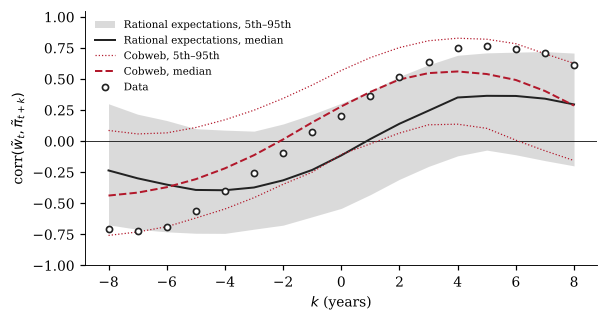

In [32]:
rng = np.random.default_rng(0)
sims_cw = np.array([sample_stats(simulate(th_cw, len(Yobs), rng, solve=solve_cobweb)) for _ in range(1000)])

fig, a = plt.subplots(figsize=(5.6, 3.0)); a.axhline(0, color=INK, lw=0.6)
a.fill_between(KS, np.percentile(sims_re[:, cc], 5, 0), np.percentile(sims_re[:, cc], 95, 0),
               color='#bdbdbd', alpha=0.55, lw=0, label='Rational expectations, 5th–95th')
a.plot(KS, np.median(sims_re[:, cc], 0), color=INK, lw=1.3, label='Rational expectations, median')
a.plot(KS, np.percentile(sims_cw[:, cc], 5, 0), color=RED, lw=0.8, ls=':')
a.plot(KS, np.percentile(sims_cw[:, cc], 95, 0), color=RED, lw=0.8, ls=':', label='Cobweb, 5th–95th')
a.plot(KS, np.median(sims_cw[:, cc], 0), color=RED, lw=1.3, ls='--', label='Cobweb, median')
a.plot(KS, stats_data[cc], 'o', ms=4, mfc='white', mec=INK, mew=1.1, label='Data')
a.set_xticks(KS[::2]); a.set_xlabel(r'$k$ (years)'); a.set_ylabel(r'corr$(\tilde w_t,\tilde\pi_{t+k})$'); a.set_ylim(-1, 1.05)
a.legend(fontsize=6.8, frameon=False, loc='upper left')
fig.tight_layout(); fig.savefig(FIGS + 'fig_cw_leadcorr.pdf')

i4 = 6 + int(np.where(KS == 4)[0][0])
print(f'k = 4: data {stats_data[i4]:.2f};  RE 95th percentile {np.percentile(sims_re[:, i4], 95):.2f};  '
      f'cobweb median {np.median(sims_cw[:, i4]):.2f}, 5-95% [{np.percentile(sims_cw[:, i4], 5):.2f}, {np.percentile(sims_cw[:, i4], 95):.2f}]')
print(f'entry response to a 1% wage increase on impact: cobweb {th_cw["eta"]:.1f}%;  '
      f'RE (demand shock) {n0 / w0:.2f}%')

### 7.4 Figure 5: impulse responses under the two models

Each model is hit by a one-standard-deviation shock as estimated in that model.

cobweb, demand shock: entry peaks at 3.3% in year 4, turns negative in year 11; the demand shock itself turns negative in year 12


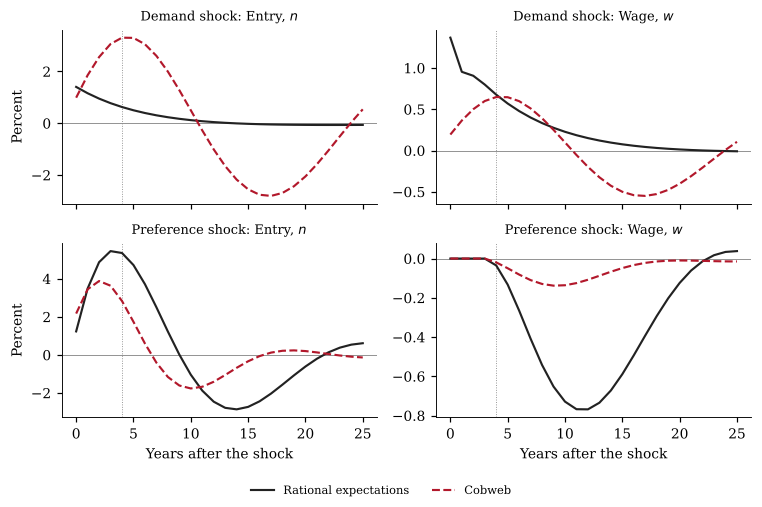

In [33]:
fig, ax = plt.subplots(2, 2, figsize=(7.0, 4.6), sharex=True)
for r, (j, name) in enumerate([(0, 'Demand shock'), (1, 'Preference shock')]):
    re_, cw_ = impulse_response(th_hat, j), impulse_response(th_cw, j, solve=solve_cobweb)
    for c, (col, title) in enumerate([('entry n', 'Entry, $n$'), ('wage w', 'Wage, $w$')]):
        a = ax[r, c]
        a.axhline(0, color=GREY, lw=0.6); a.axvline(4, color=GREY, lw=0.6, ls=':')
        a.plot(re_[col], color=INK, lw=1.4, label='Rational expectations')
        a.plot(cw_[col], color=RED, lw=1.4, ls='--', label='Cobweb')
        a.set_title(f'{name}: {title}', fontsize=8.5)
for a in ax[1]:
    a.set_xlabel('Years after the shock')
ax[0, 0].set_ylabel('Percent'); ax[1, 0].set_ylabel('Percent')
handles, labs = ax[0, 0].get_legend_handles_labels()
fig.legend(handles, labs, loc='lower center', ncol=2, fontsize=7.5, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1)); fig.savefig(FIGS + 'fig_cw_irf.pdf')

cw_d = impulse_response(th_cw, 0, solve=solve_cobweb)
print(f"cobweb, demand shock: entry peaks at {cw_d['entry n'].max():.1f}% in year {cw_d['entry n'].idxmax()}, "
      f"turns negative in year {(cw_d['entry n'] < 0).idxmax()}; the demand shock itself turns negative in year {(cw_d['shock'] < 0).idxmax()}")

## 8. Final check

The planner–household equivalence and the Riccati iteration, now at the estimated parameters.

In [34]:
check_solution(th_hat)

(a) max |P_iterated - P_direct| = 2.8e-12    (b) max |planner rule - household rule| = 1.3e-14
